# 03. Optimizer, scheduler and hyperparameters

**Question:** which training settings should the final model use?

**Already known from the EDA:** nothing. EDA used one fixed recipe (AdamW, lr 0.003, weight decay 0.01, batch size 32, dropout 0.15, class weights 1/3/2, no scheduler) and said it wasn't tuned.

Each group changes one setting while the rest stay fixed, starting from `nerkit/decisions.py`. This is cheaper than a full grid, though it can miss interactions. Inner validation controls early stopping; the table reports the held-out fold 0.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "eda").exists():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT), str(ROOT / "model")]

from IPython.display import display

from nerkit import plots
from nerkit.config import SEEDS
from nerkit.decisions import base_config
from nerkit.experiment import confirm, records_named, run_grid, summarize, top_names

NOTEBOOK = "03_training_setup"
LONGER = dict(max_epochs=10, patience=3)

def show(names, title):
    table = summarize(NOTEBOOK, baseline="reference")
    display(table.loc[[name for name in table.index if name in names]])
    plots.learning_curves(records_named(NOTEBOOK, names), title=title)

In [2]:
# The reference run for every comparison in this notebook.
run_grid(NOTEBOOK, {"reference": LONGER});

reference: F1 mix 0.856, uk 0.846, ru 0.924, 117 s on cpu


## 1. Optimizer and learning rate
SGD needs a much larger learning rate than the Adam family, so each starts from a sensible value.

adamw_lr_0.0003: F1 mix 0.831, uk 0.821, ru 0.904, 116 s on cpu


adamw_lr_0.001: F1 mix 0.846, uk 0.836, ru 0.918, 99 s on cpu


adamw_lr_0.01: F1 mix 0.836, uk 0.827, ru 0.899, 78 s on cpu


adam_lr_0.003: F1 mix 0.851, uk 0.840, ru 0.922, 108 s on cpu


rmsprop_lr_0.001: F1 mix 0.843, uk 0.832, ru 0.917, 107 s on cpu


sgd_lr_0.1: F1 mix 0.833, uk 0.822, ru 0.913, 106 s on cpu


sgd_lr_0.5: F1 mix 0.785, uk 0.774, ru 0.857, 56 s on cpu


,runs,vs_baseline,mix_f1,spread,uk_f1,ru_f1,precision,recall,uk_unseen_recall,posts_f1,labeling_f1,minutes
name,,,,,,,,,,,,
reference,1,0.000,0.856,0.0,0.846,0.924,0.848,0.864,0.669,0.832,0.617,1.950
adam_lr_0.003,1,-0.005,0.851,0.0,0.840,0.922,0.885,0.819,0.597,0.837,0.580,1.793
adamw_lr_0.001,1,-0.010,0.846,0.0,0.836,0.918,0.852,0.840,0.644,0.821,0.658,1.644
rmsprop_lr_0.001,1,-0.013,0.843,0.0,0.832,0.917,0.853,0.833,0.625,0.832,0.486,1.777
adamw_lr_0.01,1,-0.020,0.836,0.0,0.827,0.899,0.858,0.815,0.636,0.817,0.694,1.298
sgd_lr_0.1,1,-0.023,0.833,0.0,0.822,0.913,0.848,0.819,0.612,0.817,0.622,1.768
adamw_lr_0.0003,1,-0.025,0.831,0.0,0.821,0.904,0.841,0.822,0.606,0.812,0.597,1.931
sgd_lr_0.5,1,-0.071,0.785,0.0,0.774,0.857,0.851,0.729,0.417,0.777,0.583,0.925


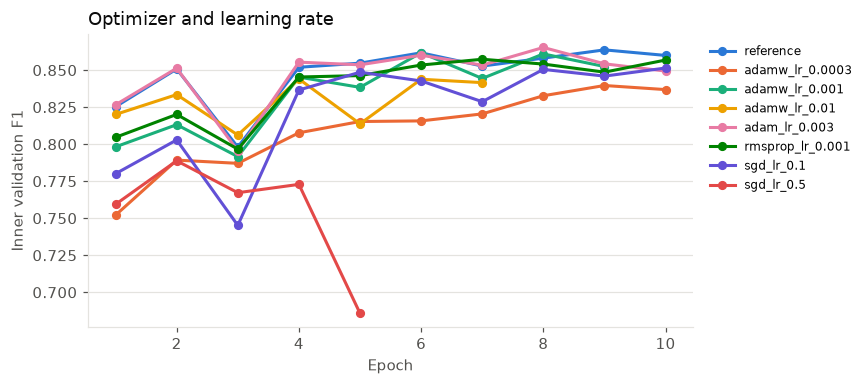

In [3]:
GROUP = {
    "adamw_lr_0.0003": dict(lr=0.0003), "adamw_lr_0.001": dict(lr=0.001), "adamw_lr_0.01": dict(lr=0.01),
    "adam_lr_0.003": dict(optimizer="adam", weight_decay=0.0),
    "rmsprop_lr_0.001": dict(optimizer="rmsprop", lr=0.001, weight_decay=0.0),
    "sgd_lr_0.1": dict(optimizer="sgd", lr=0.1, weight_decay=0.0),
    "sgd_lr_0.5": dict(optimizer="sgd", lr=0.5, weight_decay=0.0),
}
run_grid(NOTEBOOK, {name: {**LONGER, **change} for name, change in GROUP.items()})
show(["reference", *GROUP], "Optimizer and learning rate");

## 2. Scheduler
OneCycle and cosine plan the whole run ahead, so they run to the last epoch with no early stopping. Compare them at a similar training length.

onecycle: F1 mix 0.854, uk 0.844, ru 0.926, 112 s on cpu


cosine: F1 mix 0.856, uk 0.845, ru 0.930, 111 s on cpu


plateau: F1 mix 0.860, uk 0.850, ru 0.927, 109 s on cpu


,runs,vs_baseline,mix_f1,spread,uk_f1,ru_f1,precision,recall,uk_unseen_recall,posts_f1,labeling_f1,minutes
name,,,,,,,,,,,,
plateau,1,0.004,0.860,0.0,0.850,0.927,0.862,0.858,0.670,0.834,0.683,1.821
reference,1,0.000,0.856,0.0,0.846,0.924,0.848,0.864,0.669,0.832,0.617,1.950
cosine,1,-0.000,0.856,0.0,0.845,0.930,0.855,0.857,0.656,0.835,0.658,1.847
onecycle,1,-0.002,0.854,0.0,0.844,0.926,0.856,0.852,0.659,0.830,0.700,1.875


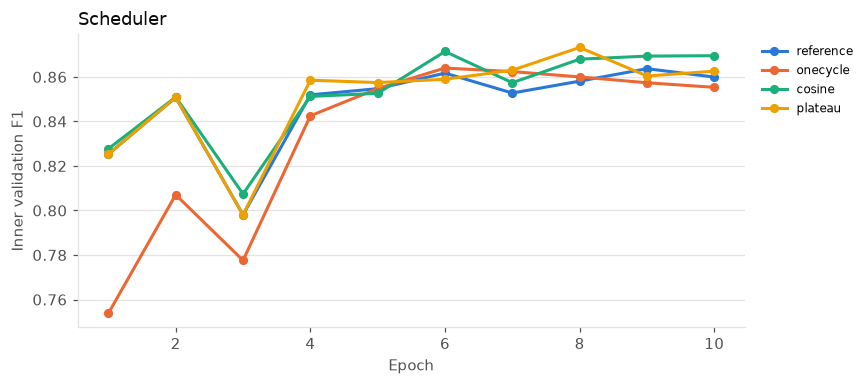

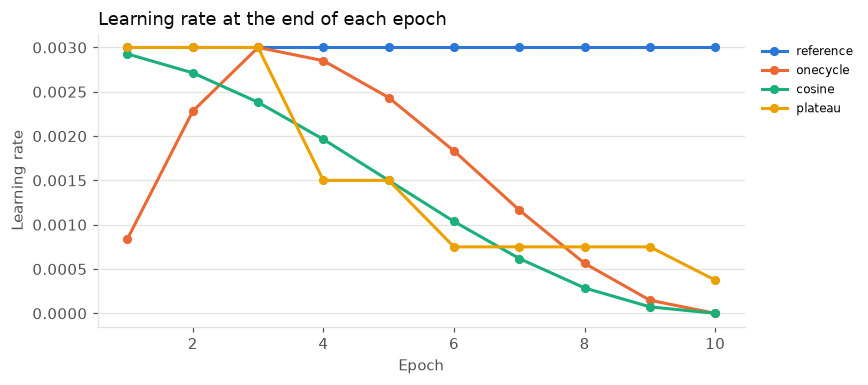

In [4]:
GROUP = {
    "onecycle": dict(scheduler="onecycle", max_epochs=10, patience=0),
    "cosine": dict(scheduler="cosine", max_epochs=10, patience=0),
    "plateau": dict(scheduler="plateau", **LONGER),
}
run_grid(NOTEBOOK, GROUP)
show(["reference", *GROUP], "Scheduler");
plots.learning_curves(records_named(NOTEBOOK, ["reference", *GROUP]), metric="lr", title="Learning rate at the end of each epoch", ylabel="Learning rate");

## 3. Batch size, dropout and weight decay

In [5]:
GROUP = {
    "batch_16": dict(batch_size=16), "batch_64": dict(batch_size=64), "batch_128": dict(batch_size=128),
    "dropout_0": dict(dropout=0.0), "dropout_0.3": dict(dropout=0.3), "dropout_0.5": dict(dropout=0.5),
    "decay_0": dict(weight_decay=0.0), "decay_0.1": dict(weight_decay=0.1),
}
run_grid(NOTEBOOK, {name: {**LONGER, **change} for name, change in GROUP.items()})
display(summarize(NOTEBOOK, baseline="reference").loc[["reference", *GROUP]])

batch_16: F1 mix 0.853, uk 0.842, ru 0.925, 139 s on cpu


batch_64: F1 mix 0.846, uk 0.836, ru 0.915, 59 s on cpu


batch_128: F1 mix 0.843, uk 0.833, ru 0.913, 50 s on cpu


dropout_0: F1 mix 0.849, uk 0.839, ru 0.921, 90 s on cpu


dropout_0.3: F1 mix 0.858, uk 0.847, ru 0.928, 108 s on cpu


dropout_0.5: F1 mix 0.846, uk 0.835, ru 0.915, 108 s on cpu


decay_0: F1 mix 0.851, uk 0.840, ru 0.922, 107 s on cpu


decay_0.1: F1 mix 0.835, uk 0.826, ru 0.898, 57 s on cpu


,runs,vs_baseline,mix_f1,spread,uk_f1,ru_f1,precision,recall,uk_unseen_recall,posts_f1,labeling_f1,minutes
name,,,,,,,,,,,,
reference,1,0.000,0.856,0.0,0.846,0.924,0.848,0.864,0.669,0.832,0.617,1.950
batch_16,1,-0.003,0.853,0.0,0.842,0.925,0.871,0.836,0.647,0.839,0.684,2.323
batch_64,1,-0.010,0.846,0.0,0.836,0.915,0.861,0.831,0.634,0.828,0.625,0.988
batch_128,1,-0.013,0.843,0.0,0.833,0.913,0.863,0.825,0.617,0.820,0.623,0.835
dropout_0,1,-0.007,0.849,0.0,0.839,0.921,0.837,0.862,0.671,0.831,0.659,1.506
dropout_0.3,1,0.001,0.858,0.0,0.847,0.928,0.852,0.863,0.675,0.840,0.667,1.801
dropout_0.5,1,-0.010,0.846,0.0,0.835,0.915,0.871,0.822,0.597,0.826,0.580,1.796
decay_0,1,-0.005,0.851,0.0,0.840,0.922,0.885,0.819,0.597,0.837,0.580,1.784
decay_0.1,1,-0.021,0.835,0.0,0.826,0.898,0.855,0.817,0.612,0.817,0.597,0.957


## 4. Class weights and gradient clipping
Class weights directly shift precision against recall, so read those columns too. A CRF loss has no class weights, so those runs are skipped automatically when the base model uses a CRF. Clipping protects against exploding gradients; turning it off is a useful health check.

no_clipping: F1 mix 0.855, uk 0.845, ru 0.923, 96 s on cpu


clip_5: F1 mix 0.855, uk 0.845, ru 0.923, 108 s on cpu


,runs,vs_baseline,mix_f1,spread,uk_f1,ru_f1,precision,recall,uk_unseen_recall,posts_f1,labeling_f1,minutes
name,,,,,,,,,,,,
reference,1,0.000,0.856,0.0,0.846,0.924,0.848,0.864,0.669,0.832,0.617,1.950
no_clipping,1,-0.001,0.855,0.0,0.845,0.923,0.858,0.853,0.663,0.844,0.716,1.607
clip_5,1,-0.001,0.855,0.0,0.845,0.923,0.886,0.827,0.605,0.829,0.618,1.800


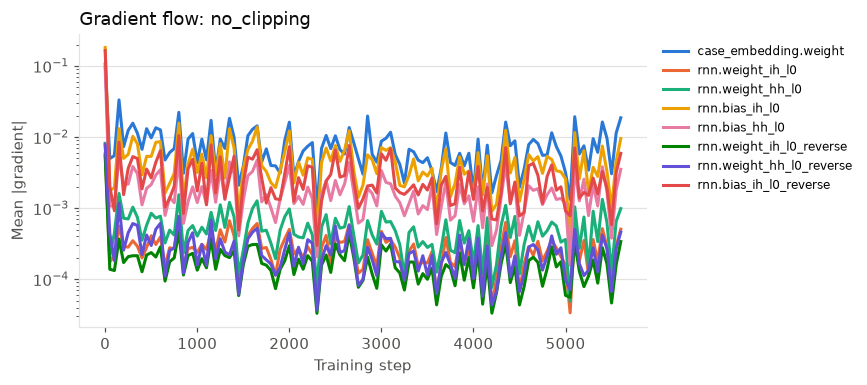

In [6]:
GROUP = {"no_clipping": dict(grad_clip=0.0), "clip_5": dict(grad_clip=5.0)}
if not base_config().crf:  # the CRF loss ignores class weights, so these runs would repeat the reference
    GROUP |= {
        "weights_1_1_1": dict(weight_b=1.0, weight_i=1.0), "weights_1_5_3": dict(weight_b=5.0, weight_i=3.0),
        "weights_1_10_5": dict(weight_b=10.0, weight_i=5.0),
    }
run_grid(NOTEBOOK, {name: {**LONGER, **change} for name, change in GROUP.items()})
display(summarize(NOTEBOOK, baseline="reference").loc[["reference", *GROUP]])
for record in records_named(NOTEBOOK, ["no_clipping"]):
    plots.gradient_flow(record)

## 5. Overall ranking and confirmation

,runs,vs_baseline,mix_f1,spread,uk_f1,ru_f1,precision,recall,uk_unseen_recall,posts_f1,labeling_f1,minutes
name,,,,,,,,,,,,
plateau,1,0.004,0.860,0.0,0.850,0.927,0.862,0.858,0.670,0.834,0.683,1.821
dropout_0.3,1,0.001,0.858,0.0,0.847,0.928,0.852,0.863,0.675,0.840,0.667,1.801
reference,1,0.000,0.856,0.0,0.846,0.924,0.848,0.864,0.669,0.832,0.617,1.950
cosine,1,-0.000,0.856,0.0,0.845,0.930,0.855,0.857,0.656,0.835,0.658,1.847
no_clipping,1,-0.001,0.855,0.0,0.845,0.923,0.858,0.853,0.663,0.844,0.716,1.607
clip_5,1,-0.001,0.855,0.0,0.845,0.923,0.886,0.827,0.605,0.829,0.618,1.800
onecycle,1,-0.002,0.854,0.0,0.844,0.926,0.856,0.852,0.659,0.830,0.700,1.875
batch_16,1,-0.003,0.853,0.0,0.842,0.925,0.871,0.836,0.647,0.839,0.684,2.323
decay_0,1,-0.005,0.851,0.0,0.840,0.922,0.885,0.819,0.597,0.837,0.580,1.784


plateau: F1 mix 0.848, uk 0.837, ru 0.923, 77 s on cpu


plateau: F1 mix 0.848, uk 0.838, ru 0.920, 77 s on cpu


dropout_0.3: F1 mix 0.847, uk 0.836, ru 0.916, 67 s on cpu


dropout_0.3: F1 mix 0.849, uk 0.838, ru 0.926, 107 s on cpu


reference: F1 mix 0.843, uk 0.832, ru 0.920, 77 s on cpu


reference: F1 mix 0.856, uk 0.846, ru 0.924, 107 s on cpu


,runs,vs_baseline,mix_f1,spread,uk_f1,ru_f1,precision,recall,uk_unseen_recall,posts_f1,labeling_f1,minutes
name,,,,,,,,,,,,
plateau,3,0.001,0.852,0.012,0.842,0.923,0.865,0.840,0.627,0.835,0.644,1.465
dropout_0.3,3,-0.000,0.851,0.011,0.840,0.923,0.851,0.852,0.658,0.834,0.655,1.571
reference,3,0.000,0.852,0.013,0.841,0.923,0.858,0.846,0.644,0.834,0.603,1.677


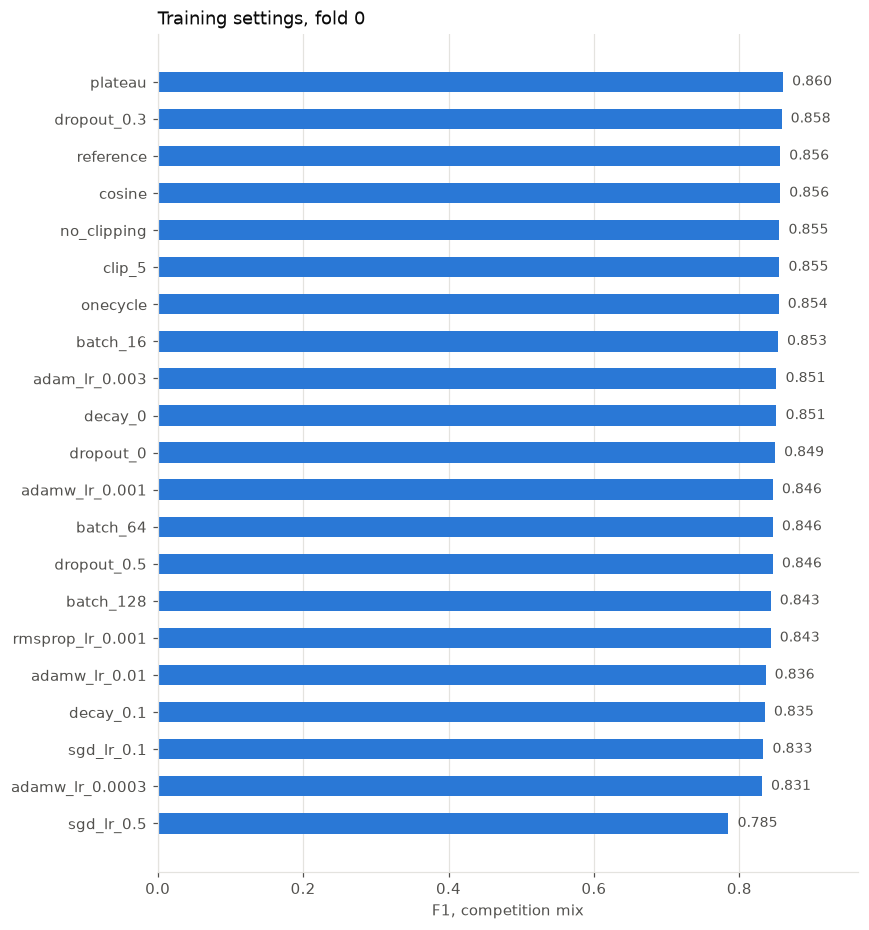

In [7]:
summary = summarize(NOTEBOOK, baseline="reference")
display(summary)
plots.scores_chart(summary, "Training settings, fold 0");
finalists = top_names(NOTEBOOK, 3)
confirm(NOTEBOOK, finalists, folds=(0,), seeds=SEEDS[1:])
display(summarize(NOTEBOOK, baseline="reference").loc[finalists])

## Results summary (fold 0, CRF GRU, 10k rows per language)

Scores are F1 mix, single seed 3012026 unless noted. The reference (the defaults) scored 0.856, 0.843 and 0.856 across three seeds (mean 0.852, spread 0.013), so only gaps above about 0.013 mean anything.

| Group | Run | F1 mix |
| --- | --- | ---: |
| Reference | AdamW, lr 0.003, no scheduler, batch 32, dropout 0.15, decay 0.01, clip 1.0 | 0.856 |
| Learning rate | 0.0003, 0.001, 0.01 | 0.831, 0.846, 0.836 |
| Optimizer | Adam, RMSprop, SGD (lr 0.1), SGD (lr 0.5) | 0.851, 0.843, 0.833, 0.785 |
| Scheduler | OneCycle, cosine, plateau (3 seeds, mean) | 0.854, 0.856, 0.860 (0.852) |
| Batch size | 16, 64, 128 | 0.853, 0.846, 0.843 |
| Dropout | 0, 0.3 (3 seeds, mean), 0.5 | 0.849, 0.858 (0.851), 0.846 |
| Weight decay | 0, 0.1 | 0.851, 0.835 |
| Gradient clipping | none, 5 | 0.855, 0.855 |

### What we learned

1. **The defaults were already at the optimum.** No setting beat the reference by more than the noise. The one apparent winner, the plateau scheduler at 0.860, fell to a mean of 0.852 over three seeds, the same as the reference. Dropout 0.3 also averaged 0.851.
2. **Learning rate 0.003 is the best of a coarse grid.** Ten times lower or higher costs 0.02 to 0.025.
3. **AdamW is a fine optimizer.** Adam without decay is a tie, RMSprop is slightly lower, and plain SGD is slower: at lr 0.1 it was still improving at epoch 10, and at lr 0.5 it became unstable (training loss rose from 0.499 to 0.606 in the last epoch).
4. **Schedulers don't help here.** OneCycle, cosine and plateau all tie with a constant rate, because early stopping already picks a good epoch.
5. **Batch size 32 is right.** 16 ties but trains about 15% slower; 64 and 128 are faster and about 0.01 worse.
6. **Regularization is balanced.** Weight decay 0.1 is too strong (training stopped at epoch 5, 0.835), while 0 and 0.01 tie.
7. **Gradient health is fine.** The largest gradients occur at the very first step (the output bias reached 8.5 and the CRF transitions 3.4), then settle one to two orders of magnitude lower and stay stable. The GRU weights sit around 1e-4 to 1e-3, so there's no vanishing or explosion in this one-layer model. Turning clipping off changed nothing (0.855), because the gradient norm is only above 1 in the first steps.
8. **Mild overfitting, handled by early stopping.** In the reference run, training loss falls from 0.664 to 0.092 while validation loss bottoms out at epoch 6 (0.261) and rises to 0.321. F1 keeps improving until epoch 8 or 9, so F1 is the right stopping criterion. The best epoch ranges from 4 to 9 across seeds, which is the main source of the seed spread.
9. **Class weights were skipped.** A CRF loss has none.

### Decisions

No training setting changes. The defaults are now written explicitly in `decisions.py`: AdamW, learning rate 0.003, weight decay 0.01, no scheduler, batch size 32, dropout 0.15 and gradient clipping 1.0.

### Caveats

- Most variants have one seed, and the grids are coarse.
- All of this was tuned on 10k rows per language. With much more data (notebook 04), the best learning rate and number of epochs may shift.